# 03 · Payoff constraints and arbitrage

As Boyd and Vandenberghe (2004) explain in *Convex optimization*, linear constraints can express feasible portfolios. Here a finite-state linear programme maximises the lowest state payoff after costs, with budget and displayed-depth bounds. The optimisation is only as reliable as its state matrix and execution assumptions.

Synthetic validation tests logic separately from the empirical market scan. All results below distinguish conditional ordinary-resolution baskets from a claim of guaranteed execution.

In [1]:
from pathlib import Path
import sys, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'kalshi_engine/client.py').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
from kalshi_engine.client import ROOT
from kalshi_engine.presentation import show_table, show_figure, equation, read
from kalshi_engine.microstructure import Book, FeePolicy, sweep, execution_fee
from kalshi_engine.arbitrage import partition_audit, temperature_payoff_states, coherence, basket, statewise_portfolio
from kalshi_engine.probability import normalise, calibrate, scores, fit_temperature, paired_block_interval
print('Kalshi Microstructure Research | recorded public-data study | no order placement')

Kalshi Microstructure Research | recorded public-data study | no order placement


In [2]:
equation(10)
equation(11)
A=np.eye(3)
known=statewise_portfolio(A,[.3,.3,.3],[10,10,10],budget=100)
assert abs(known['worst_profit']-1)<1e-8
with_gap=statewise_portfolio(np.vstack([A,np.zeros(3)]),[.3,.3,.3],[10,10,10],budget=100)
assert abs(with_gap['worst_profit'])<1e-8
show_table(pd.DataFrame([{'state_set':'Three exhaustive outcomes','worst_profit':known['worst_profit']},{'state_set':'Plus a no-winner state','worst_profit':with_gap['worst_profit']}]), 'Table N03.1. A missing payoff state can create a false arbitrage certificate.')

\Pi(\omega;\mathbf q)=\sum_i X_i(\omega)q_i-\sum_i[C_i(q_i)+F_i(q_i)] (10)

\max_{\mathbf q,g}g\quad\mathrm{s.t.}\quad A\mathbf q-\mathbf c^T\mathbf q\,\mathbf1\geq g\mathbf1,\quad0\leq\mathbf q\leq\mathbf d,\quad\mathbf c^T\mathbf q\leq B (11)

state_set,worst_profit
Three exhaustive outcomes,1.00000
Plus a no-winner state,0.00000


scenario,replications,accuracy,eligible_rate
asynchronous,500,1.00000,0.00000
coherent,500,1.00000,0.00000
exceptional_settlement,500,1.00000,0.00000
fees_remove_gap,500,1.00000,0.00000
insufficient_depth,500,1.00000,0.00000
true_gap,500,1.00000,1.00000


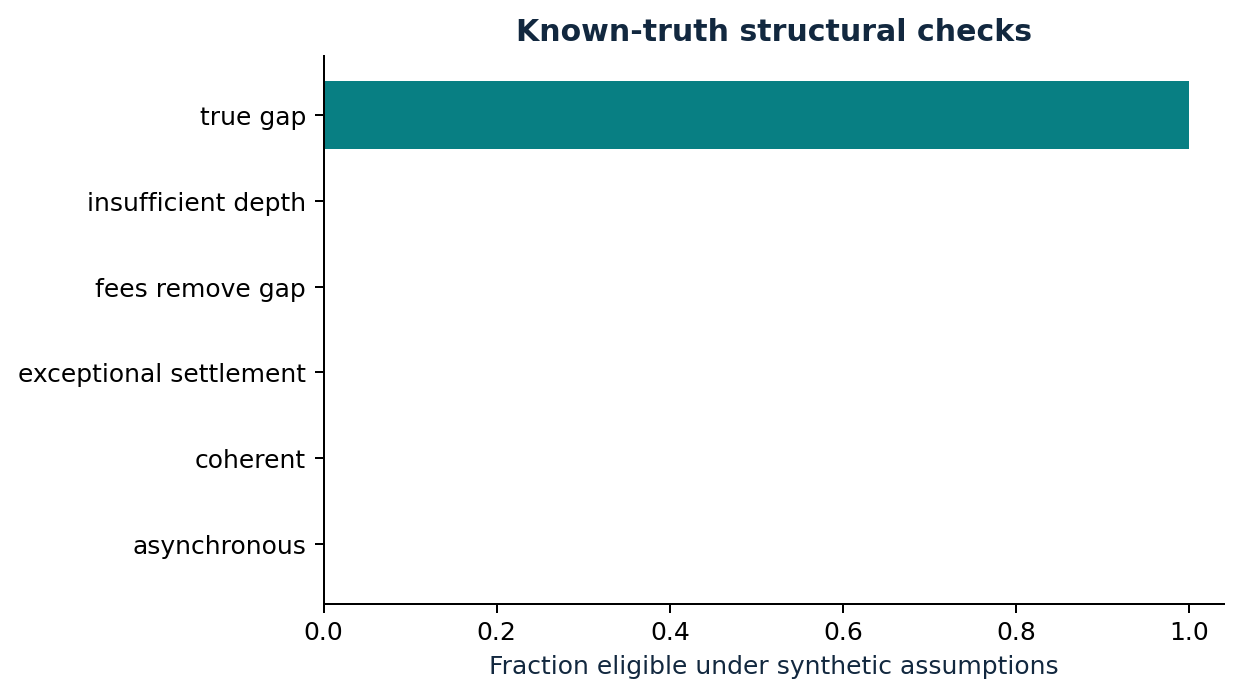

Figure 8. Six synthetic mechanisms, 500 replications each. Passing known-truth tests verifies selected logic, not real-market profitability.

Five hundred paired probability draws across six scenarios; not 3,000 independent markets.


In [3]:
summary=pd.read_csv(ROOT/'outputs/tables/synthetic-summary.csv')
show_table(summary, 'Table N03.2. Known-truth outcomes from 3,000 synthetic scenario evaluations.')
assert (summary.accuracy==1).all()
show_figure(8)
print('Five hundred paired probability draws across six scenarios; not 3,000 independent markets.')

## What the acquired sample shows

The hourly historical panel produces apparent gross basket discrepancies, but fees remove them under the stated current-fee scenario. Historical quote summaries cannot supply missing depth or enforce simultaneous fills. The brief live sample contains no positive cost-adjusted basket candidate or statewise portfolio profit. This does not establish the absence of opportunities elsewhere or at other times.

measurement,count
Historical gross quote-only gaps,34
Historical gaps after current fee scenario,0
Live positive conditional baskets,0
Live positive rechecked statewise LP,0


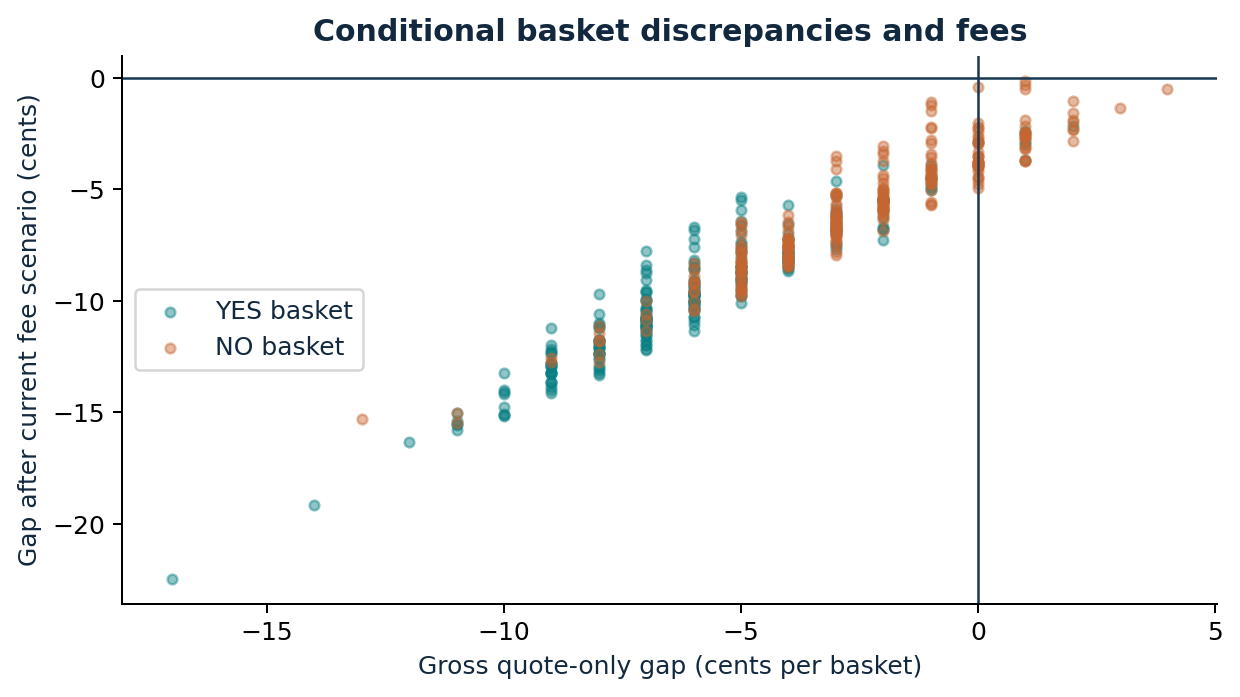

Figure 3. Conditional integer-resolution basket gaps from hourly quotes; current fee scenarios do not establish historical execution or contractual arbitrage.

In [4]:
supp=read('outputs/supplementary-results.json');live=read('outputs/live-results.json')
show_table(pd.DataFrame([{'measurement':'Historical gross quote-only gaps','count':supp['gross_positive_quote_baskets']},{'measurement':'Historical gaps after current fee scenario','count':supp['net_positive_current_fee_scenario']},{'measurement':'Live positive conditional baskets','count':live['conditional_basket_candidates']},{'measurement':'Live positive rechecked statewise LP','count':live['positive_rechecked_lp']}]), 'Table N03.3. Distinct screens; historical and live rows are not one execution funnel.')
show_figure(3)